<a href="https://colab.research.google.com/github/KananS/AIMLMonth2023/blob/main/Copy_of_Minor_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**FAKE NEWS DETECTION AND RUMOR CONTROL**

Importing the Data Dependencies

In [ ]:
import numpy as np
import pandas as pd
import re
from nltk.corpus import stopwords
from nltk.stem.porter import PorterStemmer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [ ]:
import nltk
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [ ]:
# Stopwords in English
print(stopwords.words('english'))

['i', 'me', 'my', 'myself', 'we', 'our', 'ours', 'ourselves', 'you', "you're", "you've", "you'll", "you'd", 'your', 'yours', 'yourself', 'yourselves', 'he', 'him', 'his', 'himself', 'she', "she's", 'her', 'hers', 'herself', 'it', "it's", 'its', 'itself', 'they', 'them', 'their', 'theirs', 'themselves', 'what', 'which', 'who', 'whom', 'this', 'that', "that'll", 'these', 'those', 'am', 'is', 'are', 'was', 'were', 'be', 'been', 'being', 'have', 'has', 'had', 'having', 'do', 'does', 'did', 'doing', 'a', 'an', 'the', 'and', 'but', 'if', 'or', 'because', 'as', 'until', 'while', 'of', 'at', 'by', 'for', 'with', 'about', 'against', 'between', 'into', 'through', 'during', 'before', 'after', 'above', 'below', 'to', 'from', 'up', 'down', 'in', 'out', 'on', 'off', 'over', 'under', 'again', 'further', 'then', 'once', 'here', 'there', 'when', 'where', 'why', 'how', 'all', 'any', 'both', 'each', 'few', 'more', 'most', 'other', 'some', 'such', 'no', 'nor', 'not', 'only', 'own', 'same', 'so', 'than', '

Data Pre-processing

In [ ]:
from google.colab import drive

In [ ]:
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!ls -la /content/drive/

total 16
dr-x------ 4 root root 4096 Nov  3 05:21 .Encrypted
drwx------ 4 root root 4096 Nov  3 05:21 MyDrive
dr-x------ 2 root root 4096 Nov  3 05:21 .shortcut-targets-by-id
drwx------ 5 root root 4096 Nov  3 05:21 .Trash-0


In [ ]:
!ls -la /content/

total 98392
drwxr-xr-x 1 root root      4096 Nov  3 05:21 .
drwxr-xr-x 1 root root      4096 Nov  3 04:51 ..
drwxr-xr-x 4 root root      4096 Oct 30 13:36 .config
drwx------ 5 root root      4096 Nov  3 05:21 drive
drwxr-xr-x 1 root root      4096 Oct 30 13:36 sample_data
-rw-r--r-- 1 root root 100725702 Nov  3 05:20 train.csv


In [ ]:
data_news = pd.read_csv('train.csv', encoding='ISO-8859-1')

In [ ]:
data_news

,id,title,author,text,label
0,0,House Dem Aide: We Didnât Even See Comeyâs...,Darrell Lucus,House Dem Aide: We Didnât Even See Comeyâs...,1
1,1,"FLYNN: Hillary Clinton, Big Woman on Campus - ...",Daniel J. Flynn,Ever get the feeling your life circles the rou...,0
2,2,Why the Truth Might Get You Fired,Consortiumnews.com,"Why the Truth Might Get You Fired October 29, ...",1
3,3,15 Civilians Killed In Single US Airstrike Hav...,Jessica Purkiss,Videos 15 Civilians Killed In Single US Airstr...,1
4,4,Iranian woman jailed for fictional unpublished...,Howard Portnoy,Print \nAn Iranian woman has been sentenced to...,1
...,...,...,...,...,...
21276,20795,Rapper T.I.: Trump a âPoster Child For White...,Jerome Hudson,Rapper T. I. unloaded on black celebrities who...,0
21277,20796,"N.F.L. Playoffs: Schedule, Matchups and Odds -...",Benjamin Hoffman,When the Green Bay Packers lost to the Washing...,0
21278,20797,Macyâs Is Said to Receive Takeover Approach ...,Michael J. de la Merced and Rachel Abrams,The Macyâs of today grew from the union of s...,0
21279,20798,"NATO, Russia To Hold Parallel Exercises In Bal...",Alex Ansary,"NATO, Russia To Hold Parallel Exercises In Bal...",1


In [ ]:
data_news.shape

(21281, 5)

In [ ]:
# First 5 rows of dataframe
data_news.head()

,id,title,author,text,label
0,0,House Dem Aide: We Didnât Even See Comeyâs...,Darrell Lucus,House Dem Aide: We Didnât Even See Comeyâs...,1
1,1,"FLYNN: Hillary Clinton, Big Woman on Campus - ...",Daniel J. Flynn,Ever get the feeling your life circles the rou...,0
2,2,Why the Truth Might Get You Fired,Consortiumnews.com,"Why the Truth Might Get You Fired October 29, ...",1
3,3,15 Civilians Killed In Single US Airstrike Hav...,Jessica Purkiss,Videos 15 Civilians Killed In Single US Airstr...,1
4,4,Iranian woman jailed for fictional unpublished...,Howard Portnoy,Print \nAn Iranian woman has been sentenced to...,1


In [ ]:
# Count of the number of missing values in the given dataset
data_news.isnull().sum()

,0
id,0
title,567
author,2011
text,40
label,0


In [ ]:
# Replacing null values with an empty string
data_news = data_news.fillna('')

In [ ]:
# Merging the author name & news title
data_news['content'] = data_news['author']+' '+ data_news['title']

In [ ]:
print(data_news['content'])

0        Darrell Lucus House Dem Aide: We Didnât Even...
1        Daniel J. Flynn FLYNN: Hillary Clinton, Big Wo...
2        Consortiumnews.com Why the Truth Might Get You...
3        Jessica Purkiss 15 Civilians Killed In Single ...
4        Howard Portnoy Iranian woman jailed for fictio...
                               ...                        
21276    Jerome Hudson Rapper T.I.: Trump a âPoster C...
21277    Benjamin Hoffman N.F.L. Playoffs: Schedule, Ma...
21278    Michael J. de la Merced and Rachel Abrams Macy...
21279    Alex Ansary NATO, Russia To Hold Parallel Exer...
21280              David Swanson What Keeps the F-35 Alive
Name: content, Length: 21281, dtype: object


In [ ]:
# Separating data & label
X = data_news.drop(columns='label', axis=1)
Y = data_news['label']

In [ ]:
print(X)
print(Y)

          id                                              title  \
0          0  House Dem Aide: We Didnât Even See Comeyâs...   
1          1  FLYNN: Hillary Clinton, Big Woman on Campus - ...   
2          2                  Why the Truth Might Get You Fired   
3          3  15 Civilians Killed In Single US Airstrike Hav...   
4          4  Iranian woman jailed for fictional unpublished...   
...      ...                                                ...   
21276  20795  Rapper T.I.: Trump a âPoster Child For White...   
21277  20796  N.F.L. Playoffs: Schedule, Matchups and Odds -...   
21278  20797  Macyâs Is Said to Receive Takeover Approach ...   
21279  20798  NATO, Russia To Hold Parallel Exercises In Bal...   
21280  20799                          What Keeps the F-35 Alive   

                                          author  \
0                                  Darrell Lucus   
1                                Daniel J. Flynn   
2                             Consortiu

In [ ]:
f_data = data_news.dropna()

In [ ]:
# Total null values present
f_data.isnull().sum()

,0
id,0
title,0
author,0
text,0
label,0
content,0


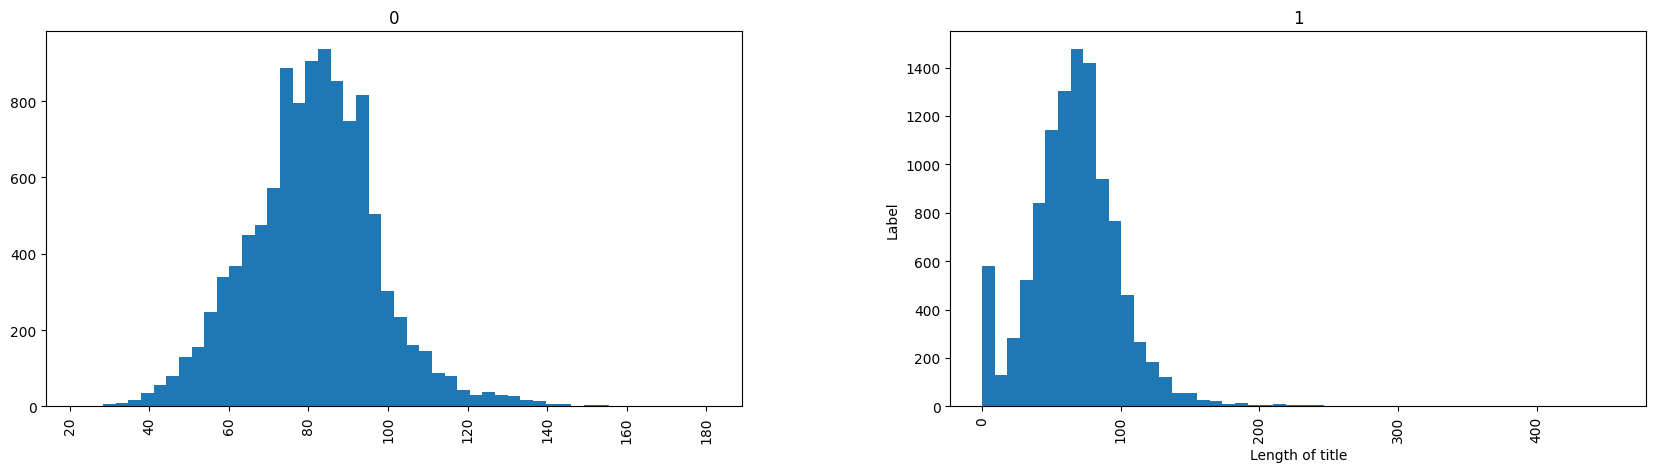

In [ ]:
# Histogram of the dataset
import matplotlib.pyplot as plt
f_data['length'] = f_data['title'].apply(len)
f_data.hist(column='length', by='label', figsize=(20,5), bins=50)
plt.xlabel('Length of title')
plt.ylabel('Label')
plt.show()

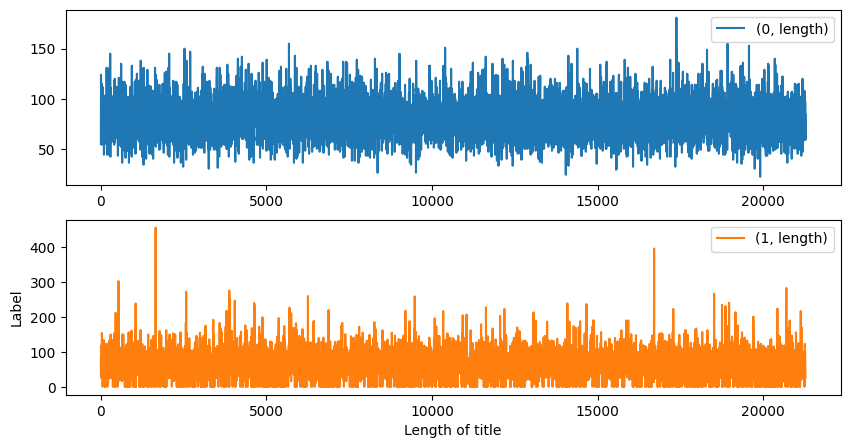

In [ ]:
# Visualization of data
f_data.plot(column='length', by='label', figsize=(10,5))
plt.xlabel('Length of title')
plt.ylabel('Label')
plt.show()

Stemming



In [ ]:
port_stem = PorterStemmer()

In [ ]:
def stemming(content):
  stemmed_content = re.sub('[^a-zA-Z]', ' ', content)
  stemmed_content = stemmed_content.lower()
  stemmed_content = stemmed_content.split()
  stemmed_content = [port_stem.stem(word) for word in stemmed_content if not word in stopwords.words('english')]
  stemmed_content = ' '.join(stemmed_content)
  return stemmed_content

In [ ]:
from nltk.stem.porter import PorterStemmer
import re

# Initialize the stemmer
port_stem = PorterStemmer()

# Define the stemming function
def stemming(content):
    # Remove non-alphabetic characters and convert to lowercase
    stemmed_content = re.sub('[^a-zA-Z]', ' ', content)
    stemmed_content = stemmed_content.lower()
    stemmed_content = stemmed_content.split()

    # Apply stemming to each word
    stemmed_content = [port_stem.stem(word) for word in stemmed_content]
    stemmed_content = ' '.join(stemmed_content)

    return stemmed_content

# Now apply it to your dataframe
data_news['content'] = data_news['content'].apply(stemming)

In [ ]:
print(data_news['content'])

0        darrel lucu hous dem aid we didn t even see co...
1        daniel j flynn flynn hillari clinton big woman...
2        consortiumnew com whi the truth might get you ...
3        jessica purkiss civilian kill in singl us airs...
4        howard portnoy iranian woman jail for fiction ...
                               ...                        
21276    jerom hudson rapper t i trump a poster child f...
21277    benjamin hoffman n f l playoff schedul matchup...
21278    michael j de la merc and rachel abram maci s i...
21279    alex ansari nato russia to hold parallel exerc...
21280                   david swanson what keep the f aliv
Name: content, Length: 21281, dtype: object


In [ ]:
# Separating data & label
X = data_news['content'].values
Y = data_news['label'].values

In [ ]:
print(X)

['darrel lucu hous dem aid we didn t even see comey s letter until jason chaffetz tweet it'
 'daniel j flynn flynn hillari clinton big woman on campu breitbart'
 'consortiumnew com whi the truth might get you fire' ...
 'michael j de la merc and rachel abram maci s is said to receiv takeov approach by hudson s bay the new york time'
 'alex ansari nato russia to hold parallel exercis in balkan'
 'david swanson what keep the f aliv']


In [ ]:
print(Y)

[1 0 1 ... 0 1 1]


In [ ]:
Y.shape

(21281,)

In [ ]:
# Converting text to numerical data
vectorizer = TfidfVectorizer()
vectorizer.fit(X)

X = vectorizer.transform(X)

In [ ]:
print(X)

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 275664 stored elements and shape (21281, 17232)>
  Coords	Values
  (0, 272)	0.24003298385890343
  (0, 2501)	0.32692882517727634
  (0, 2977)	0.21956654131046222
  (0, 3619)	0.3200483041853309
  (0, 3811)	0.24003298385890343
  (0, 4028)	0.2632868532411331
  (0, 4997)	0.20731001235436503
  (0, 7041)	0.19429628953120842
  (0, 7642)	0.155432094432354
  (0, 7734)	0.21956654131046222
  (0, 8673)	0.25868692845159674
  (0, 8953)	0.3233319729760259
  (0, 13533)	0.22760559246984477
  (0, 15767)	0.2529580147860434
  (0, 16060)	0.28423153739992646
  (0, 16591)	0.19179758473853206
  (1, 1512)	0.2900865101076887
  (1, 1910)	0.15277278343763676
  (1, 2241)	0.37811341925581315
  (1, 2831)	0.18818811585475476
  (1, 3587)	0.2603997917592944
  (1, 5528)	0.7058603294891823
  (1, 6850)	0.18761015939314588
  (1, 10754)	0.15843315831187554
  (1, 16897)	0.2962773610469005
  :	:
  (21278, 10355)	0.07783574757296423
  (21278, 12197)	0.2406392487459264

Dataset splitting into training data and test data

In [ ]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.2, stratify=Y, random_state=2)

Model Training

In [ ]:
model = LogisticRegression()

In [ ]:
model.fit(X_train, Y_train)

LogisticRegression()

In [ ]:
from sklearn.tree import DecisionTreeClassifier
classifier = DecisionTreeClassifier(criterion='entropy', random_state=0)
classifier.fit(X_train, Y_train)

DecisionTreeClassifier(criterion='entropy', random_state=0)

Evaluation of accuracy

In [ ]:
# 1. Split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.3, random_state=42)
print(f'✓ Split complete: {len(X_train)} train, {len(X_test)} test')

# 2. Vectorize
vectorizer = TfidfVectorizer(max_features=500)
X_train = vectorizer.fit_transform(X_train)
X_test = vectorizer.transform(X_test)
print(f'✓ Vectorization complete: {X_train.shape[1]} features')

# 3. Train
model = LogisticRegression(C=0.001, max_iter=1000)
model.fit(X_train, Y_train)
print('✓ Model training complete')

# 4. Evaluate
X_test_pred = model.predict(X_test)
test_accuracy = accuracy_score(Y_test, X_test_pred)
print(f'✓ Test accuracy: {test_accuracy:.4f}')

✓ Split complete: 14896 train, 6385 test
✓ Vectorization complete: 500 features
✓ Model training complete
✓ Test accuracy: 0.8366


In [ ]:
# Accuracy of training data
X_train_pred = model.predict(X_train)
training_data_accuracy = accuracy_score(X_train_pred, Y_train)

In [ ]:
print('Accuracy score of the training data : ', training_data_accuracy)

Accuracy score of the training data :  0.8355263157894737


In [ ]:
# Accuracy of test data
X_test_pred = model.predict(X_test)
test_data_accuracy = accuracy_score(X_test_pred, Y_test)

In [ ]:
print('Accuracy score of the test data : ', test_data_accuracy)

Accuracy score of the test data :  0.8366483946750196


Making a Predictive System



In [ ]:
X_new = X_test[3]

prediction = model.predict(X_new)
print(prediction)

if (prediction[0]==0):
  print('The news is Real & Not a Rumor')
else:
  print('The news is Fake & Rumor')

[0]
The news is Real & Not a Rumor


In [ ]:
print(Y_test[3])

1


In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

In [ ]:
import copy
from nltk.corpus import stopwords

In [ ]:
# Removing punctuation marks from the title
import string
def text_process(title):
    nop = [char for char in title if char not in string.punctuation]
    nop = ''.join(nop)
    return [word for word in nop.split() if word in word.lower() not in stopwords.words('english')]

In [ ]:
# Using the Naive Model with its parameters
piplineTitle = Pipeline([
    ('bow', CountVectorizer(analyzer=text_process)),
    ('tfidf', TfidfTransformer()),
    ('classifier', MultinomialNB()),
])

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(f_data['title'], f_data['label'], test_size=0.2, random_state=123)

In [ ]:
# Fitting the dataset
print(piplineTitle.fit(x_train, y_train))

Pipeline(steps=[('bow',
                 CountVectorizer(analyzer=<function text_process at 0x79080c0a0b80>)),
                ('tfidf', TfidfTransformer()),
                ('classifier', MultinomialNB())])


In [ ]:
Y_pred = piplineTitle.fit(x_train, y_train).predict(x_test)
Y_pred

array([1, 1, 1, ..., 0, 1, 1])

In [ ]:
# Using Confusion Matrix
cnf_matrix = confusion_matrix(Y_test, Y_pred)
print('Cnfusion Matrix',cnf_matrix)

Cnfusion Matrix [[ 170 1952]
 [ 179 1956]]


Text(95.72222222222221, 0.5, 'real & not rumor')

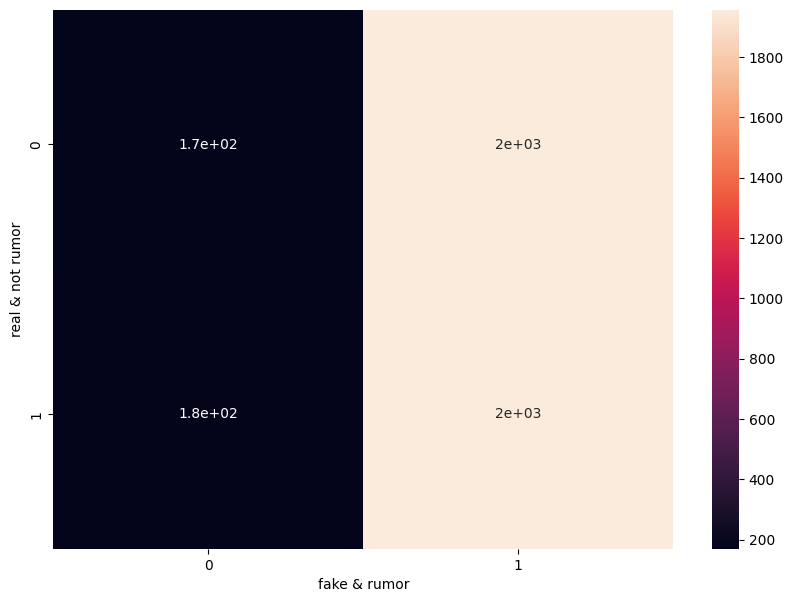

In [ ]:
# Visualization of results
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize = (10,7))
sns.heatmap(cnf_matrix, annot=True)
plt.xlabel('fake & rumor')
plt.ylabel('real & not rumor')